In [ ]:
from sklearn.datasets import make_circles

n_samples = 1000

X, y = make_circles(
    n_samples, noise=0.3, random_state=42
)

print(f"First 5 X features:\n{X[:5]}")
print(f"\nFirst 5 y labels:\n{y[:5]}")

First 5 X features:
[[ 0.59171471  0.43674853]
 [-0.45745002  0.36160118]
 [-1.01069349  0.83042101]
 [-0.87169639  0.41407292]
 [ 0.48803455 -0.87258708]]

First 5 y labels:
[1 1 1 1 0]


In [ ]:
X.shape, X.ndim

((1000, 2), 2)

In [ ]:
import pandas as pd

circles = pd.DataFrame({
    "X1": X[:, 0], "X2": X[:, 1],
    "label" : y
})

circles.head(5)

,X1,X2,label
0,0.591715,0.436749,1
1,-0.457450,0.361601,1
2,-1.010693,0.830421,1
3,-0.871696,0.414073,1
4,0.488035,-0.872587,0


In [ ]:
circles.iloc[0]

,0
X1,0.591715
X2,0.436749
label,1.000000


In [ ]:
circles.loc[0]

,0
X1,0.591715
X2,0.436749
label,1.000000


In [ ]:
circles['X1']

,X1
0,0.591715
1,-0.457450
2,-1.010693
3,-0.871696
4,0.488035
...,...
995,0.312050
996,-1.069302
997,-0.019858
998,0.542692


In [ ]:
circles.label.value_counts()

,count
label,
1,500
0,500


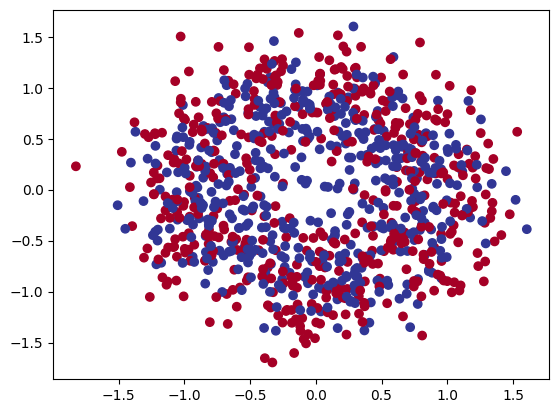

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(x=X[:, 0],
            y=X[:, 1],
            c=y,
            cmap=plt.cm.RdYlBu
            );

In [ ]:
X.shape, y.shape

((1000, 2), (1000,))

In [ ]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [ ]:
X = torch.from_numpy(X).to(device).type(torch.float)
y= torch.from_numpy(y).to(device).type(torch.float)

In [ ]:
type(X), type(y)

(torch.Tensor, torch.Tensor)

In [ ]:
X.dtype

torch.float32

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

len(X_train), len(X_test), len(y_train), len(y_test)

(800, 200, 800, 200)

In [ ]:
from torch import nn

class ClassificationModelV0(nn.Module):
  def __init__(self) -> None:
    super().__init__()
    self.linear_layer_1 = nn.Linear(in_features=2, out_features=5)
    self.linear_layer_2 = nn.Linear(in_features=5, out_features=1)

  def forward(self, x):
    return self.linear_layer_2(self.linear_layer_1(x))

In [ ]:
model_01 = ClassificationModelV0()

In [ ]:
model_01.to(device)

ClassificationModelV0(
  (linear_layer_1): Linear(in_features=2, out_features=5, bias=True)
  (linear_layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [ ]:
model_01.state_dict()

OrderedDict([('linear_layer_1.weight',
              tensor([[ 0.5406,  0.5869],
                      [-0.1657,  0.6496],
                      [-0.1549,  0.1427],
                      [-0.3443,  0.4153],
                      [ 0.6233, -0.5188]], device='cuda:0')),
             ('linear_layer_1.bias',
              tensor([0.6146, 0.1323, 0.5224, 0.0958, 0.3410], device='cuda:0')),
             ('linear_layer_2.weight',
              tensor([[-0.0631,  0.3448,  0.0661, -0.2088,  0.1140]], device='cuda:0')),
             ('linear_layer_2.bias', tensor([-0.2060], device='cuda:0'))])

In [ ]:
model_0 = nn.Sequential(
    nn.Linear(in_features=2, out_features=5),
    nn.Linear(in_features=5, out_features=1)
).to(device)

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.SGD(
    params=model_01.parameters(),
    lr=0.1
)



In [ ]:
def accuracy_fn(y_true, y_pred):
  correct = torch.eq(y_true, y_pred).sum().item()
  acc = (correct / len(y_pred)) * 100
  return acc

In [ ]:
y_logits = model_01(X_test.to(device))[:5]
y_logits

tensor([[-0.1260],
        [-0.0898],
        [-0.1738],
        [-0.0805],
        [-0.2075]], device='cuda:0', grad_fn=<SliceBackward0>)

In [ ]:
y_pred_probs = torch.sigmoid(y_logits)
y_pred_probs

tensor([[0.4686],
        [0.4776],
        [0.4567],
        [0.4799],
        [0.4483]], device='cuda:0', grad_fn=<SigmoidBackward0>)

In [ ]:
y_preds = torch.round(y_pred_probs)
y_preds

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.]], device='cuda:0', grad_fn=<RoundBackward0>)

In [ ]:
y_pred_labels = torch.round(torch.sigmoid(model_01(X_test.to(device))))[:5]
y_pred_labels

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.]], device='cuda:0', grad_fn=<SliceBackward0>)

In [ ]:
torch.eq(y_pred_labels, y_preds)

tensor([[True],
        [True],
        [True],
        [True],
        [True]], device='cuda:0')

In [ ]:
torch.manual_seed(42)

epochs = 100

X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
  model_01.train()

  y_logits = model_01(X_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))

  loss = loss_fn(y_logits, y_train)
  acc = accuracy_fn(y_true=y_train, y_pred = y_pred)

  optimizer.zero_grad

  loss.backward()

  optimizer.step()

  model_01.eval()

  with torch.inference_mode():

    test_logits = model_01(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits, y_test)

    test_acc = accuracy_fn(y_true = y_test, y_pred=test_pred)


  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 0.69584, Accuracy: 50.00% | Test loss: 0.69722, Test acc: 50.00%
Epoch: 10 | Loss: 0.69439, Accuracy: 54.37% | Test loss: 0.69850, Test acc: 49.00%
Epoch: 20 | Loss: 0.69304, Accuracy: 51.75% | Test loss: 0.69407, Test acc: 48.50%
Epoch: 30 | Loss: 0.69494, Accuracy: 47.00% | Test loss: 0.69359, Test acc: 50.00%
Epoch: 40 | Loss: 0.69533, Accuracy: 50.00% | Test loss: 0.69635, Test acc: 50.00%
Epoch: 50 | Loss: 0.69312, Accuracy: 46.88% | Test loss: 0.69416, Test acc: 50.00%
Epoch: 60 | Loss: 0.69435, Accuracy: 49.75% | Test loss: 0.69612, Test acc: 50.00%
Epoch: 70 | Loss: 0.69511, Accuracy: 54.50% | Test loss: 0.70006, Test acc: 47.50%
Epoch: 80 | Loss: 0.69321, Accuracy: 51.25% | Test loss: 0.69554, Test acc: 47.50%
Epoch: 90 | Loss: 0.69466, Accuracy: 50.00% | Test loss: 0.69486, Test acc: 50.00%


In [ ]:
import requests
from pathlib import Path

if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary



helper_functions.py already exists, skipping download


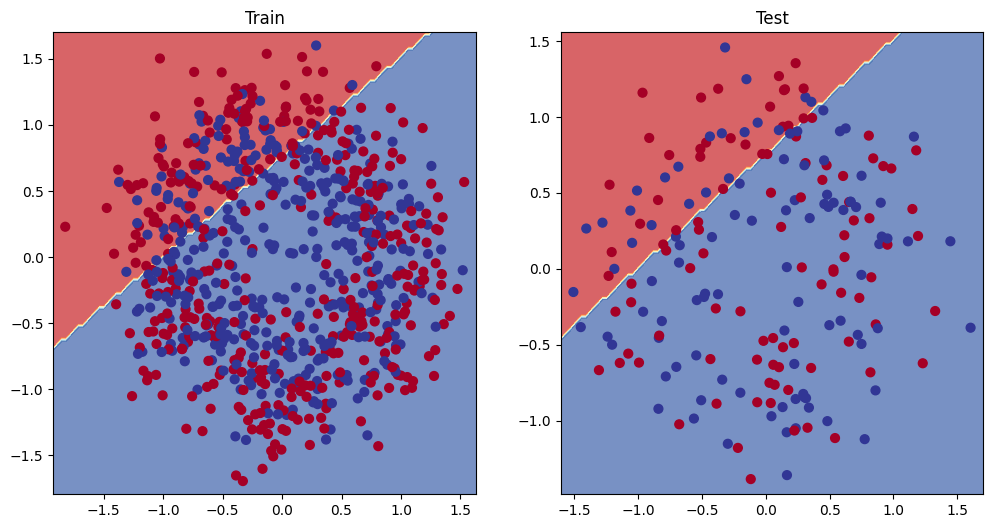

In [ ]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)

In [ ]:
class CirclModelv1(nn.Module):
  def __init__(self) -> None:
    super().__init__()
    self.layer_1 = nn.Linear(in_features=2, out_features=10)
    self.layer_2 = nn.Linear(in_features=10, out_features=10)
    self.layer_3 = nn.Linear(in_features=10, out_features=1)

  def forward(self, x):
    return self.layer_3(self.layer_2(self.layer_1(x)))

model_1 = CirclModelv1().to(device)
model_1

CirclModelv1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_1.parameters(), lr= 0.1)

In [ ]:
torch.manual_seed(42)

epochs = 1000
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
  ### Training
    # 1. Forward pass
    y_logits = model_1(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits)) # logits -> prediction probabilities -> prediction labels

    # 2. Calculate loss/accuracy
    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train,
                      y_pred=y_pred)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    ### Testing
    model_1.eval()
    with torch.inference_mode():
        # 1. Forward pass
        test_logits = model_1(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        # 2. Caculate loss/accuracy
        test_loss = loss_fn(test_logits,
                            y_test)
        test_acc = accuracy_fn(y_true=y_test,
                               y_pred=test_pred)

    # Print out what's happening every 10 epochs
    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


Epoch: 0 | Loss: 0.69370, Accuracy: 51.12% | Test loss: 0.69300, Test acc: 48.50%
Epoch: 100 | Loss: 0.69301, Accuracy: 50.12% | Test loss: 0.69388, Test acc: 50.50%
Epoch: 200 | Loss: 0.69298, Accuracy: 51.62% | Test loss: 0.69428, Test acc: 48.50%
Epoch: 300 | Loss: 0.69297, Accuracy: 52.25% | Test loss: 0.69440, Test acc: 50.00%
Epoch: 400 | Loss: 0.69297, Accuracy: 52.00% | Test loss: 0.69443, Test acc: 49.50%
Epoch: 500 | Loss: 0.69297, Accuracy: 52.00% | Test loss: 0.69444, Test acc: 49.50%
Epoch: 600 | Loss: 0.69297, Accuracy: 52.00% | Test loss: 0.69444, Test acc: 49.50%
Epoch: 700 | Loss: 0.69297, Accuracy: 52.00% | Test loss: 0.69445, Test acc: 49.50%
Epoch: 800 | Loss: 0.69297, Accuracy: 52.00% | Test loss: 0.69445, Test acc: 49.50%
Epoch: 900 | Loss: 0.69297, Accuracy: 52.00% | Test loss: 0.69445, Test acc: 49.50%


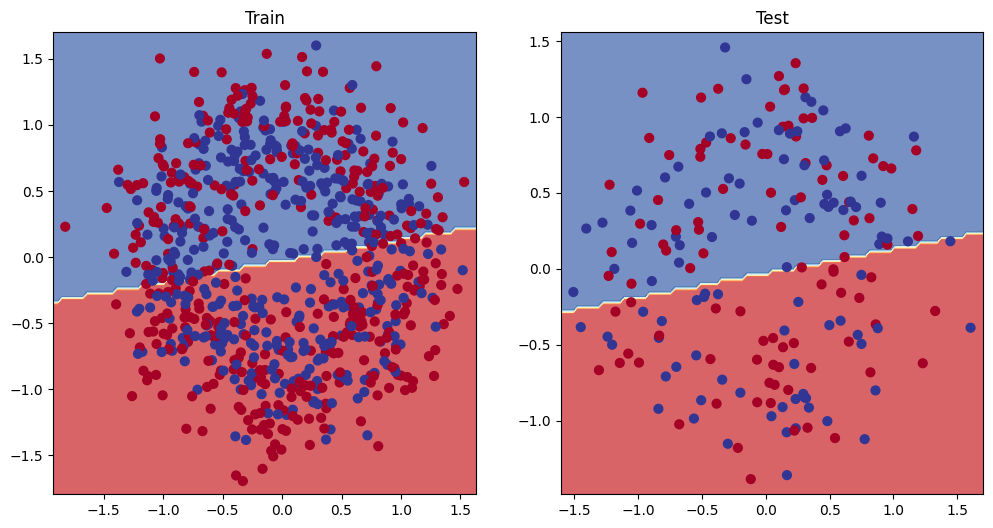

In [ ]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_1, X_test, y_test)

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

In [ ]:
n_samples = 10000

X, y = make_circles(n_samples=n_samples, noise = 0.03, random_state=42)

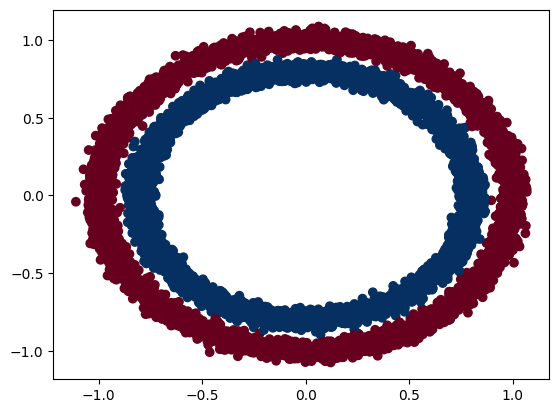

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdBu);

In [ ]:
import torch
from sklearn.model_selection import train_test_split

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train[:5], y_train[:5]

(tensor([[ 0.2029, -1.0081],
         [-0.1717, -0.9750],
         [ 0.5565,  0.5440],
         [ 0.1194, -1.0153],
         [ 0.3515,  0.7450]]),
 tensor([0., 0., 1., 0., 1.]))

In [ ]:
from torch import nn
class CirclModelV2(nn.Module):
  def __init__(self) -> None:
    super().__init__()
    self.layer_1 = nn.Linear(in_features=2, out_features=20)
    self.layer_2 = nn.Linear(in_features=20, out_features=20)
    self.layer_3 = nn.Linear(in_features=20, out_features=1)
    self.relu = nn.ReLU()

  def forward(self, x):
    return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

In [ ]:
model_3 = CirclModelV2().to(device)
print(model_3)

CirclModelV2(
  (layer_1): Linear(in_features=2, out_features=20, bias=True)
  (layer_2): Linear(in_features=20, out_features=20, bias=True)
  (layer_3): Linear(in_features=20, out_features=1, bias=True)
  (relu): ReLU()
)


In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_3.parameters(), lr = 0.001)

In [ ]:
# Fit the model
torch.manual_seed(42)
epochs = 100000

# Put all data on target device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
    # 1. Forward pass
    y_logits = model_3(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits)) # logits -> prediction probabilities -> prediction labels

    # 2. Calculate loss and accuracy
    loss = loss_fn(y_logits, y_train) # BCEWithLogitsLoss calculates loss using logits
    acc = accuracy_fn(y_true=y_train,
                      y_pred=y_pred)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backward
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    ### Testing
    model_3.eval()
    with torch.inference_mode():
      # 1. Forward pass
      test_logits = model_3(X_test).squeeze()
      test_pred = torch.round(torch.sigmoid(test_logits)) # logits -> prediction probabilities -> prediction labels
      # 2. Calculate loss and accuracy
      test_loss = loss_fn(test_logits, y_test)
      test_acc = accuracy_fn(y_true=y_test,
                             y_pred=test_pred)

    # Print out what's happening
    if epoch % 10000 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Accuracy: {test_acc:.2f}%")

Epoch: 0 | Loss: 0.69408, Accuracy: 48.33% | Test Loss: 0.69357, Test Accuracy: 48.80%
Epoch: 10000 | Loss: 0.69074, Accuracy: 52.75% | Test Loss: 0.69083, Test Accuracy: 52.45%
Epoch: 20000 | Loss: 0.68726, Accuracy: 56.39% | Test Loss: 0.68749, Test Accuracy: 56.25%
Epoch: 30000 | Loss: 0.68342, Accuracy: 59.19% | Test Loss: 0.68375, Test Accuracy: 60.00%
Epoch: 40000 | Loss: 0.67762, Accuracy: 63.21% | Test Loss: 0.67809, Test Accuracy: 63.45%
Epoch: 50000 | Loss: 0.66813, Accuracy: 69.55% | Test Loss: 0.66873, Test Accuracy: 69.15%
Epoch: 60000 | Loss: 0.65189, Accuracy: 72.65% | Test Loss: 0.65252, Test Accuracy: 72.15%
Epoch: 70000 | Loss: 0.62264, Accuracy: 81.79% | Test Loss: 0.62315, Test Accuracy: 80.90%
Epoch: 80000 | Loss: 0.56573, Accuracy: 92.90% | Test Loss: 0.56608, Test Accuracy: 93.95%
Epoch: 90000 | Loss: 0.45968, Accuracy: 99.21% | Test Loss: 0.46070, Test Accuracy: 99.15%


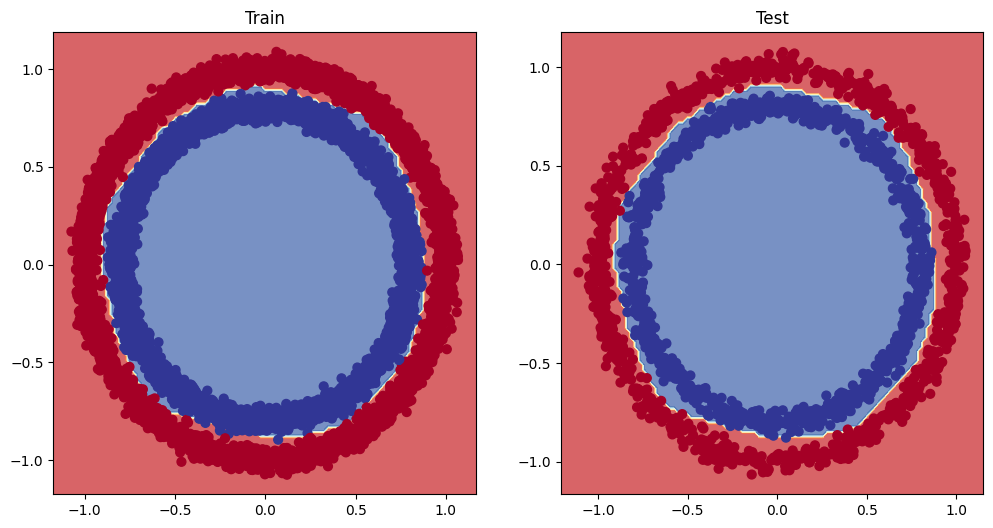

In [ ]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_3, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_3, X_test, y_test)

In [ ]:
# Make predictions
model_3.eval()
with torch.inference_mode():
    y_preds = torch.round(torch.sigmoid(model_3(X_test))).squeeze()
len(y_preds), len(y_test)
torch.eq(y_preds, y_test).sum().item()

1996